# 09 모델 검증용 분할 설계 — 고장 사건 단위 전진 검증

1. 입력 준비 — 전체 기간(4월 1일 ~ 8월 31일)의 상태와 고장 사건 7건
2. 무작위 분할을 쓰면 안 되는 이유
3. 고장 사건 단위 전진 검증 — 폴드 6개
4. 폴드별 행 수와 고장 건수
5. 모델링에서 지켜야 할 규칙
6. 분할표 저장 — `data/processed/validation_splits.csv`, `docs/validation_split.json`

이 노트북은 모델을 학습하지 않습니다. **모델링 담당자가 그대로 가져다 쓸 분할 기준**을 정하고, 행마다
어느 폴드에서 학습용인지 시험용인지 적어 둔 표를 만드는 것이 목적입니다. 전체 기간을 날짜로 한 번에
자르는 분할은 쓰지 않고, 고장 사건을 기준으로 나눕니다. 계산 코드는 `src/pump_validation.py`에 있습니다.

## 1. 입력 준비

원본 `sensor.csv`에서 시각과 `machine_status`만 씁니다. 센서 값은 분할을 정하는 데 필요 없습니다.
고장 사건은 `BROKEN` 행(7건)이고, 각 사건의 회복 종료는 그 뒤 처음 `NORMAL`로 돌아온 시각입니다.

In [ ]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

cwd = Path.cwd()
project_root = next(
    (folder for folder in (cwd, *cwd.parents)
     if (folder / "src" / "pump_validation.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("kkobugi 저장소 또는 notebooks 폴더에서 실행하세요.")
sys.path.insert(0, str(project_root))

from src.pump_missingness_audit import MINUTE, default_source, read_sensor_data
from src.plot_style import use_korean_font
from src.pump_validation import assign_folds, count_by_group, event_folds, failure_events

print("그래프 글꼴:", use_korean_font())
figure_dir = project_root / "figures/pump_validation"
figure_dir.mkdir(parents=True, exist_ok=True)

source = default_source()
raw = read_sensor_data(source)
timestamps = pd.to_datetime(raw["timestamp"], errors="raise")
if raw.empty or timestamps.isna().any() or not timestamps.diff().iloc[1:].eq(MINUTE).all():
    raise ValueError("원본의 시각이 비어 있지 않고 1분 간격인지 확인하세요.")
index = pd.DatetimeIndex(timestamps, name="timestamp")
status = raw["machine_status"].set_axis(index).rename("machine_status")
sensor_columns = [column for column in raw if column.startswith("sensor_")]

events = failure_events(status)
print(f"원본 {source.name} · {len(status):,}행 · {index[0]} ~ {index[-1]} · 고장 {len(events)}건")
display(events.assign(month=events["start"].dt.month).set_index("event"))
print("월별 고장 건수:", events["start"].dt.month.value_counts().sort_index().to_dict())

그래프 글꼴: NanumGothic


원본 sensor.csv · 220,320행 · 2018-04-01 00:00:00 ~ 2018-08-31 23:59:00 · 고장 7건


,start,recovery_end,recovery_minutes,month
event,,,,
1,2018-04-12 21:55:00,2018-04-13 13:40:00,945,4
2,2018-04-18 00:30:00,2018-04-20 04:21:00,3111,4
3,2018-05-19 03:18:00,2018-05-20 01:11:00,1313,5
4,2018-05-25 00:30:00,2018-05-25 10:36:00,606,5
5,2018-06-28 22:00:00,2018-07-04 17:51:00,8391,6
6,2018-07-08 00:11:00,2018-07-08 00:53:00,42,7
7,2018-07-25 14:00:00,2018-07-25 15:16:00,76,7


월별 고장 건수: {4: 2, 5: 2, 6: 1, 7: 2}


## 2. 무작위 분할을 쓰면 안 되는 이유

1분 간격 자료는 인접한 행이 거의 같은 값입니다. 행을 무작위로 섞어 나누면 시험 행의 1분 전·후 행이
학습에 들어가 있어, 모델이 사실상 답을 보고 맞히는 셈이 됩니다. 아래는 센서별로 "현재 값과 1분 전
값의 상관계수"를 구한 것입니다. 대부분 0.99 이상이면 인접 행이 사실상 같은 표본이라는 뜻입니다.

회복 구간(RECOVERING, 14,477행)도 마찬가지입니다. 한 사건의 회복 구간이 학습과 시험에 나뉘어 들어가면
"회복 중"을 맞히는 것은 쉬워지고, 성능은 실제보다 높게 나옵니다. 따라서 **시간 순서를 지키고, 한 고장
사건의 앞뒤 구간은 같은 쪽에** 두어야 합니다.

날짜 하나로 전체 기간을 앞뒤로 자르는 방법도 시간 순서는 지키지만, 고장이 7건뿐이라 시험 쪽에 고장이
한두 건만 남아 "몇 건 중 몇 건을 잡았는가"를 말하기 어렵습니다. 그래서 고장 사건을 하나씩 시험하는
방식을 씁니다.

In [ ]:
sensor_values = raw[sensor_columns].astype("float64").set_axis(index)
lag1 = pd.Series({
    column: sensor_values[column].autocorr(lag=1) for column in sensor_columns
}, name="1분 지연 자기상관").dropna()
summary = pd.DataFrame({
    "센서 수": [len(lag1), int(lag1.ge(0.99).sum()), int(lag1.ge(0.95).sum())],
}, index=["계산 가능", "0.99 이상", "0.95 이상"])
display(summary.T)
print("자기상관이 가장 낮은 센서 5개:")
display(lag1.nsmallest(5).round(4).to_frame())

,계산 가능,0.99 이상,0.95 이상
센서 수,51,45,50


자기상관이 가장 낮은 센서 5개:


,1분 지연 자기상관
sensor_44,0.9303
sensor_37,0.9564
sensor_27,0.9795
sensor_09,0.9832
sensor_31,0.9856


## 3. 고장 사건 단위 전진 검증

고장 사건을 하나씩 시험 대상으로 삼고, **그 이전 자료로만** 학습합니다.

- k번째 사건의 **시험 구간**: 직전 사건의 회복 종료 다음 분부터 k번째 사건의 회복 종료까지.
  고장 전 정상 구간과 고장·회복 구간이 모두 들어갑니다.
- **학습 구간**: 자료 시작(4월 1일)부터 시험 구간 직전까지.
- 학습 구간에 고장이 2건 이상 있어야 하므로 3번째 사건부터 폴드를 만듭니다(5개).
- 마지막 사건 이후 ~ 8월 31일은 고장이 없는 시험 구간(`fold_after_last`)으로 두어 오경보만 봅니다.

폴드가 뒤로 갈수록 학습 자료가 늘어나는 **전진(expanding window) 방식**이라, 운영에서 "지금까지 자료로
학습해 다음 고장을 맞히는" 상황과 같습니다. 전체 기간의 모든 행이 어느 폴드에서든 학습 또는 시험에
쓰입니다.

In [ ]:
folds = event_folds(events, index, min_train_events=2)
folds_view = folds.assign(
    train_days=((folds["train_end"] - folds["train_begin"]) / pd.Timedelta(days=1)).round(1),
    test_days=((folds["test_end"] - folds["test_begin"]) / pd.Timedelta(days=1)).round(1),
).set_index("fold")
display(folds_view)

,test_failure,train_begin,train_end,test_begin,test_end,train_failures,train_days,test_days
fold,,,,,,,,
fold_event_3,2018-05-19 03:18:00,2018-04-01,2018-04-20 04:21:00,2018-04-20 04:22:00,2018-05-20 01:11:00,2,19.2,29.9
fold_event_4,2018-05-25 00:30:00,2018-04-01,2018-05-20 01:11:00,2018-05-20 01:12:00,2018-05-25 10:36:00,3,49.0,5.4
fold_event_5,2018-06-28 22:00:00,2018-04-01,2018-05-25 10:36:00,2018-05-25 10:37:00,2018-07-04 17:51:00,4,54.4,40.3
fold_event_6,2018-07-08 00:11:00,2018-04-01,2018-07-04 17:51:00,2018-07-04 17:52:00,2018-07-08 00:53:00,5,94.7,3.3
fold_event_7,2018-07-25 14:00:00,2018-04-01,2018-07-08 00:53:00,2018-07-08 00:54:00,2018-07-25 15:16:00,6,98.0,17.6
fold_after_last,NaT,2018-04-01,2018-07-25 15:16:00,2018-07-25 15:17:00,2018-08-31 23:59:00,7,115.6,37.4


## 4. 폴드별 행 수와 고장 건수

폴드마다 학습·시험 구간의 행 수, 상태별 행 수, 그 구간에서 **시작한 고장 건수**입니다. 모든 폴드에서
시험 구간의 고장은 정확히 1건(`fold_after_last`는 0건)이고, 회복 구간이 학습과 시험에 나뉘어 들어간
경우가 없는지 확인합니다.

In [ ]:
fold_table = assign_folds(index, folds)
fold_counts = pd.concat(
    {name: count_by_group(fold_table[name], status, events).reindex(["train", "test"])
     for name in fold_table.columns},
    names=["fold", "role"],
)
display(fold_counts)

# 회복 구간(고장 시작 ~ 회복 종료)이 학습·시험 양쪽에 걸치는 폴드가 있는지 확인합니다.
split_events = [
    (name, int(event["event"]))
    for name in fold_table.columns
    for _, event in events.iterrows()
    if fold_table.loc[event["start"]: event["recovery_end"], name].nunique() > 1
]
print("회복 구간이 학습·시험에 걸친 경우:", split_events or "없음")

status                 BROKEN  NORMAL  RECOVERING    rows  failures_started
fold            role                                                       
fold_event_3    train       2   23566        4054   27622                 2
                test        1   41697        1312   43010                 1
fold_event_4    train       3   65263        5366   70632                 3
                test        1    7159         605    7765                 1
fold_event_5    train       4   72422        5971   78397                 4
                test        1   49644        8390   58035                 1
fold_event_6    train       5  122066       14361  136432                 5
                test        1    4700          41    4742                 1
fold_event_7    train       6  126766       14402  141174                 6
                test        1   25267          75   25343                 1
fold_after_last train       7  152033       14477  166517                 7
                test        0   53803           0   53803                 0

회복 구간이 학습·시험에 걸친 경우: 없음


## 5. 모델링에서 지켜야 할 규칙

1. 결측 처리 기준, 스케일링 통계, 피처 선택, 이상치 기준은 **폴드의 학습 구간에서만** 계산하고 시험
   구간에 그대로 적용합니다. 폴드마다 다시 계산합니다.
2. 08의 rolling·변화량 피처는 과거 값만 쓰므로 폴드 경계를 넘어 계산해도 누수가 아닙니다. 다만 전체
   기간 선형보간(04·05 노트북)은 결측 뒤의 값을 쓰므로 **모델 입력에는 쓰지 않습니다**. 전방 채움을
   씁니다.
3. 한 고장 사건의 정상·고장·회복 구간은 항상 같은 쪽(학습 또는 시험)에 둡니다. 위 4절에서 확인했습니다.
4. 시험 구간 결과를 보고 모델이나 임계값을 고치면 그 폴드는 더 이상 독립 평가가 아닙니다. 폴드별 결과를
   모두 모아 한 번에 봅니다.
5. 결과는 행 단위 지표와 함께 **고장 사건 단위**(5건 중 몇 건을 미리 잡았는지, 첫 경보가 고장보다 몇 분
   앞섰는지, `fold_after_last`에서 오경보가 몇 번 울렸는지)로 정리합니다.

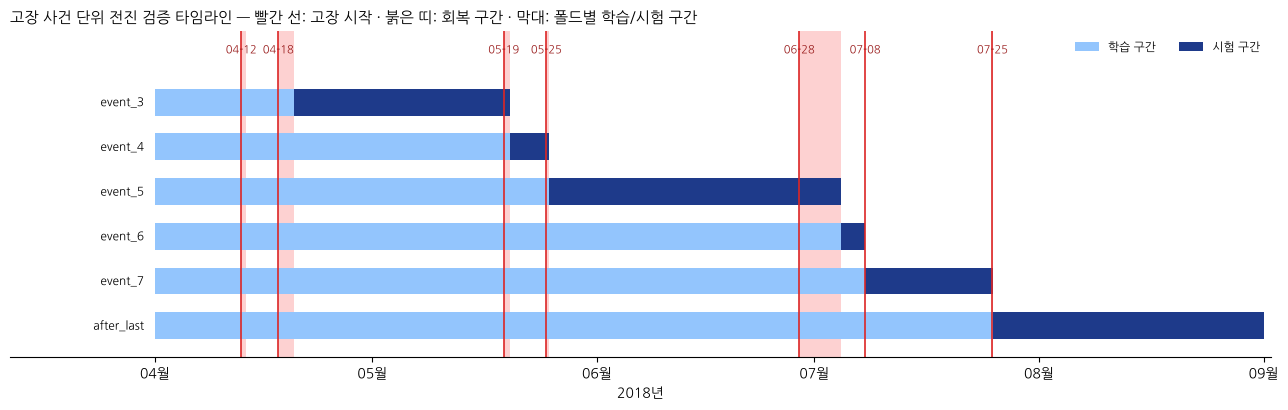

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4.2))
day = pd.Timedelta(days=1)
origin = index[0]
to_days = lambda t: (t - origin) / day

# 상태 띠: 회복 구간을 붉게
recovering = status.eq("RECOVERING").to_numpy()
runs = np.flatnonzero(np.diff(np.concatenate([[0], recovering.astype(int), [0]])))
for begin, end in zip(runs[::2], runs[1::2]):
    ax.axvspan(to_days(index[begin]), to_days(index[end - 1]), color="#fca5a5", alpha=.5, lw=0)
for _, event in events.iterrows():
    ax.axvline(to_days(event["start"]), color="#dc2626", lw=1.2)
    ax.text(to_days(event["start"]), 6.5, event["start"].strftime("%m-%d"), ha="center", fontsize=8, color="#991b1b")

# 폴드 막대
for row, (_, fold) in enumerate(folds.iterrows()):
    y = 5.4 - row
    ax.barh(y, to_days(fold["train_end"]) - to_days(fold["train_begin"]), left=to_days(fold["train_begin"]),
            height=.6, color="#93c5fd", label="학습 구간" if row == 0 else None)
    ax.barh(y, to_days(fold["test_end"]) - to_days(fold["test_begin"]), left=to_days(fold["test_begin"]),
            height=.6, color="#1e3a8a", label="시험 구간" if row == 0 else None)
    ax.text(-1.5, y, fold["fold"].replace("fold_", ""), ha="right", va="center", fontsize=8.5)

ax.set_xlim(-20, to_days(index[-1]) + 1)
ax.set_ylim(-.3, 7)
ax.set_yticks([])
month_starts = pd.date_range("2018-04-01", "2018-09-01", freq="MS")
ax.set_xticks([to_days(m) for m in month_starts], [m.strftime("%m월") for m in month_starts])
ax.set_xlabel("2018년")
ax.set_title("고장 사건 단위 전진 검증 타임라인 — 빨간 선: 고장 시작 · 붉은 띠: 회복 구간 · 막대: 폴드별 학습/시험 구간",
             loc="left", fontsize=11)
ax.legend(loc="upper right", fontsize=8.5, ncol=2, frameon=False)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig(figure_dir / "validation_split_timeline.png", dpi=150)
plt.show()

## 6. 분할표 저장

`data/processed/validation_splits.csv`에 행마다 `fold_event_3 … fold_after_last` 열(값은 train / test / none)을
저장합니다. 모델링 담당자는 이 표를 `timestamp`로 합쳐서 그대로 행을 나누면 됩니다. `data/`는
`.gitignore`에 있으므로 팀원은 이 노트북을 실행해 재생성합니다. 폴드 정의와 집계는 저장소에 포함되는
`docs/validation_split.json`에도 기록합니다.

In [ ]:
splits = pd.concat([status, fold_table], axis=1).reset_index()
output_dir = project_root / "data/processed"
output_dir.mkdir(parents=True, exist_ok=True)
csv_path = output_dir / "validation_splits.csv"
splits.to_csv(csv_path, index=False)
reloaded = pd.read_csv(csv_path)
if len(reloaded) != len(splits) or list(reloaded.columns) != list(splits.columns):
    raise ValueError("저장한 CSV를 다시 읽은 결과가 다릅니다.")
print(f"저장 {csv_path.relative_to(project_root).as_posix()} · {len(splits):,}행 × {splits.shape[1]}열")

def stamp(value):
    return None if pd.isna(value) else pd.Timestamp(value).strftime("%Y-%m-%d %H:%M:%S")

spec = {
    "generated_by": "notebooks/09_pump_validation_split.ipynb",
    "period": {"start": stamp(index[0]), "end": stamp(index[-1]), "rows": int(len(status))},
    "method": "고장 사건 단위 전진 검증 (expanding window). 날짜 기준 단일 분할은 쓰지 않음",
    "rule": [
        "결측 처리·스케일링·피처 선택·이상치 기준은 폴드의 학습 구간에서만 계산",
        "모델 입력에는 전체 기간 선형보간 대신 전방 채움 사용 (08 피처와 동일)",
        "한 고장 사건의 정상·고장·회복 구간은 같은 쪽에 둠",
        "시험 구간 결과로 모델·임계값을 고치지 않음",
        "결과는 고장 사건 단위(적중 건수·선행 시간·무고장 구간 오경보)로도 정리",
    ],
    "failure_events": [
        {"event": int(e["event"]), "start": stamp(e["start"]), "recovery_end": stamp(e["recovery_end"]),
         "recovery_minutes": int(e["recovery_minutes"])}
        for _, e in events.iterrows()
    ],
    "event_folds": {
        "columns": list(fold_table.columns),
        "values": ["train", "test", "none"],
        "definition": "시험 구간 = 직전 고장 회복 종료 다음 분 ~ 해당 고장 회복 종료, 학습 구간 = 자료 시작 ~ 그 이전",
        "folds": [
            {"fold": f["fold"], "test_failure": stamp(f["test_failure"]),
             "train": [stamp(f["train_begin"]), stamp(f["train_end"])],
             "test": [stamp(f["test_begin"]), stamp(f["test_end"])],
             "train_failures": int(f["train_failures"]),
             "counts": json.loads(count_by_group(fold_table[f["fold"]], status, events)
                                  .reindex(["train", "test"]).to_json(orient="index"))}
            for _, f in folds.iterrows()
        ],
    },
}
spec_path = project_root / "docs/validation_split.json"
spec_path.write_text(json.dumps(spec, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(f"저장 {spec_path.relative_to(project_root).as_posix()}")

저장 data/processed/validation_splits.csv · 220,320행 × 8열
저장 docs/validation_split.json


## 모델링 담당자에게

```python
import pandas as pd
splits = pd.read_csv("data/processed/validation_splits.csv", parse_dates=["timestamp"])

fold = "fold_event_5"                      # 폴드 하나
train = splits[splits[fold] == "train"]
test = splits[splits[fold] == "test"]

# 모든 폴드를 돌 때
folds = [c for c in splits.columns if c.startswith("fold_")]
```

08의 피처는 `from src.pump_features import load_prepared, build_features` →
`features = build_features(load_prepared()["values"])`로 만들고, `timestamp`로 이 표와 합치면 됩니다. 고장별 결과는
`docs/validation_split.json`의 `event_folds.folds[*].test_failure`를 기준으로 정리하면 됩니다.